# **SATELLITE SIMULATION**

In this notebook, we will formulate the mathematics involved with describing satellites that orbit a hypothetical 2D planet in perfectly circular orbits. The purpose will be to extract meaningful satellite access windows from a simulated system of satellites. These access windows are specific time periods when given satellites are within the line-of-sight of a ground station and allow for the transfer of data.    

### 1. Theory

We begin by assuming a planet with a radius $r_E$ and a satellite in circular orbit with a radius $(r_E + h)$ where $h$ is the height from the ground,

[DIAGRAM]

Using the law of sines, we can solve for the elevation angle $\epsilon_0$,

$$
\text{cos}(\epsilon_0) = \frac{h+r_E}{d} \text{sin} \left[ \beta_0(t) \right]
$$

Note that $\beta_0(t) = \theta(t) - s$ is time-dependent. From applying the cosine rule we attain a formula for the line-of-sight distance $d$,

$$
d^2 = (r_E+h)^2 + r_E^2 - 2 r_E (r_E+h)\text{cos}\left[ (\theta(t) - s) \right]
$$

Combining the formulae gives,

$$
\text{cos}(\epsilon_0) = \frac{\text{sin} \left[ \beta_0(t) \right]}{\sqrt{1 + R^2 - 2R \text{cos}\left[ \beta_0(t) \right]}} \quad R = \frac{r_E}{r_E + h}
$$

We can use the identity $\text{sin}^2(\epsilon_0) + \text{cos}^2(\epsilon_0) = 1$ to write,

$$
\text{sin}(\epsilon_0) = \frac{\text{cos} \left[ \beta_0(t) \right] - R}{\sqrt{1 + R^2 - 2R \text{cos}\left[ \beta_0(t) \right]}}
$$

The elevation angle is between $0$ and $\pi/2$ (satellite is directly above the ground station). Therefore, the satellite is visible when $\epsilon_0 > 0$. This means that 

### 2. Basic Orbital Mechanics

Now that we have worked out the mathematics of the elevation angle $\epsilon_0$, we should determine the relative angular velocity $\omega$ around the planet. The relative angular velocity of the satellite to the ground station $G$ is given by,

$$
\omega = \omega_0 \pm \omega_E
$$

where $-$ is taken when the satellite orbitis the earth in the same direction as its rotation (prograde) while $+$ is taken when it orbits against the planet's rotation (retrograde). Newton's law of gravitation tell us that,

$$
\underbrace{\frac{GMm}{(h+r_E)^2}}_{F} \hat{r} = ma \hat{r} 
$$

Assuming perfectly circular motion, $a = v^2/r$. Given that $v = \omega_0 r$, we find that:

$$
\frac{GM}{(h+r_E)^2} = \omega_0^2 (h+r_E) \quad \Longrightarrow \quad \omega_0 = \sqrt{\frac{GM}{(h+r_E)^3}}
$$

This allows us to calculate the relative velocity $\omega$ of any satellite in our model from only its height $h$.

### 2. Simulation

Now we simulate a single satellite in orbit around a planet with a radius $r_e = 6000 \ \text{km}$, mass of $M = 6 \times 10^{24} \ \text{kg}$ and a rotation speed of $\omega_E = 4.35 \times 10^{-3} \ \text{rad} \text{min}^{-1}$. The satellite has an orbit height of $h = 500 \ \text{km}$ which gives an angular velocity of $\omega_0 = 0.072 \ \text{rad} \text{min}^{-1}$. Assuming the satellite has a prograde orbit, its relative velocity is $\omega = 0.067 \ \text{rad} \text{min}^{-1}$. Using our formula to calculate the elevation angles,

In [2]:
# Importing,
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# PARAMETERS
rE = 6000
h = 500
omega = 0.067
s = np.pi/3

# Pre-calculations,
t = np.linspace(start=0, stop=2*np.pi/omega, num=1000) 
R = rE/(rE + h)
r = rE + h
beta = omega*t - s 

# Visibility calculations,
delta = np.mod(omega*t - s, 2*np.pi)
beta  = np.minimum(delta, 2*np.pi - delta)
epsilon = np.arcsin((np.cos(beta)-R)/np.sqrt(1+R**2-2*R*np.cos(beta)))
visible = epsilon >= 0

We can visualise this using the code below,

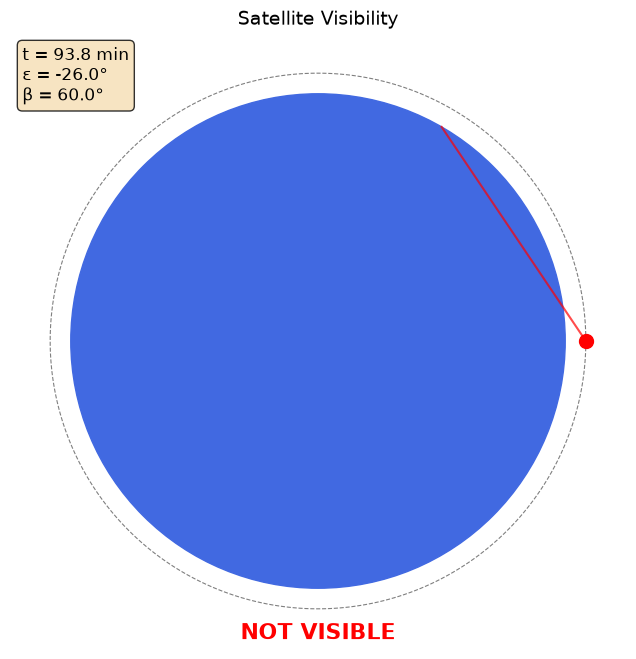

In [3]:
# Creating figure,
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect("equal")
ax.set_xlim(-r*1.15, r*1.15)
ax.set_ylim(-r*1.15, r*1.15)
ax.axis("off")
ax.set_title("Satellite Visibility", fontsize=14)

# Earth,
earth = plt.Circle((0, 0), rE, color="royalblue", alpha=1, zorder=2)
ax.add_patch(earth)

# Station,
gs_x, gs_y = rE*np.cos(s), rE*np.sin(s)
ax.plot(gs_x, gs_y, markersize=12, label="G", zorder=5, color="black")

# Orbit,
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(r*np.cos(theta), r*np.sin(theta), "k--", lw=0.8, alpha=0.5)
sat_dot, = ax.plot([], [], "ro", markersize=10, zorder=5)
los_line, = ax.plot([], [], "r-", lw=1.5, alpha=0.7)

# status text
status_text = ax.text(0, -r*1.05, '', ha='center', va='top',
                      fontsize=16, fontweight='bold')

# elevation text
elev_text = ax.text(0.02, 0.98, '', transform=ax.transAxes,
                    ha='left', va='top', fontsize=12,
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

def init():
    sat_dot.set_data([], [])
    los_line.set_data([], [])
    status_text.set_text('')
    elev_text.set_text('')
    return sat_dot, los_line, status_text, elev_text

def update(frame):
    # satellite position
    theta_sat = omega * t[frame]
    sat_x = r * np.cos(theta_sat)
    sat_y = r * np.sin(theta_sat)
    sat_dot.set_data([sat_x], [sat_y])

    # line of sight
    los_line.set_data([gs_x, sat_x], [gs_y, sat_y])

    # status
    if visible[frame]:
        status_text.set_text('VISIBLE')
        status_text.set_color('green')
        los_line.set_color('green')
    else:
        status_text.set_text('NOT VISIBLE')
        status_text.set_color('red')
        los_line.set_color('red')

    # elevation readout
    elev_text.set_text(f't = {t[frame]:.1f} min\n'
                       f'ε = {np.degrees(epsilon[frame]):.1f}°\n'
                       f'β = {np.degrees(beta[frame]):.1f}°')

    return sat_dot, los_line, status_text, elev_text

anim = FuncAnimation(fig, update, frames=len(t),
                     init_func=init, blit=True, interval=30)

# Saving animation,
anim.save(filename="satellite_simulation.html", writer="html")

### 3. Modelling Satellite Systems

Now that we have worked out the mathematics of a single satellite and when it is in view from a ground station, we can build a system of satellites. The majority of low Earth orbit (LEO) satellites are used for communication, internet and geolocation purposes. In our system, we will create concentric rings of satellite trains inspired by satellite constellations like Starlink. For the $n$-th satellite in the the $m$-th ring its orbital phase is given by,

$$
\phi_{n, m} = \frac{2\pi n}{N(m)} + \phi_0
$$

where $N$ is the number of satellites in the train. All satellites in the train are at the same height $h$ and therefore have the same angular velocity $\omega_0$. The properties of a ring are its orbit type, height, phase offset $\phi_0$ and download rate. We assume that all satellites in a given ring have the same fixed rate $R$. The location of a satellite in a ring is defined solely by its phase $\phi_{n, m}$ while its other properties are inherited. In total, our system has $M=3$ rings,  

| Ring Name | Orbit Type| Orbit Height $h$ (km) | Number of Satellites $N$ | Angular Velocity $\omega_0$ | Phase Offset $\phi_0$ (rad) | Transfer Rate (Mbps) |
|----------|:-------------:|------:|------:|------:|------:|------:|
| LEO-A | Prograde | 500 | 25 | TBC | $\pi/5$  | 250 |
| LEO-B | Retrograde | 1000 | 10 | TBC | $\pi/7$ | 100 |
| LEO-C | Prograde | 2000 | 5 | TBC | $\pi/9$ | 25 |
    
The location of the ground stations $G_1$, $G_2$ and $G_3$ are $s_1 = \pi/3$, $s_2 = 2\pi/3$ and $s_3 = 4\pi/3$ respectively. Let us now create an objects for the satellites, ground station and system itself. This will provide us for an easy to use interface for making calculations,

In [4]:
class SatelliteSystem:
    """Class to represent a satellite system with multiple satellites and ground stations."""
    def __init__(self, planetary_radius, planetary_mass, planetary_angular_velocity, G=6.67430e-11):
        self.sats = []
        self.ground_stations = []
        self.planetary_radius = planetary_radius
        self.planetary_mass = planetary_mass
        self.planetary_angular_velocity = planetary_angular_velocity
        self.G = G

    def add_sat(self, sat):
        sat.planetary_radius = self.planetary_radius
        sat.planetary_mass = self.planetary_mass
        sat.planetary_angular_velocity = self.planetary_angular_velocity
        sat.G = self.G
        self.sats.append(sat)

    def add_station(self, station):
        self.ground_stations.append(station)

    def compute_window(self, sat, station, interval, delta_t=1000, format=False):
        """Compute the visibility of a satellite from a ground station at time t."""

        # PARAMETERS
        rE = self.planetary_radius
        h = sat.altitude
        omega_0 = sat._compute_omega()
        s = station.position
        phi = sat.phase_angle

        # Pre-calculations,
        t = np.linspace(start=interval[0], stop=interval[1], num=delta_t) 
        R = rE/(rE + h)

        if sat.orbit_prograde:
            omega_rel = omega_0 - self.planetary_angular_velocity
        else:
            omega_rel = omega_0 + self.planetary_angular_velocity

        # Visibility calculations,
        delta = np.mod(omega_rel*t - s + phi, 2*np.pi)
        beta  = np.minimum(delta, 2*np.pi - delta)
        epsilon = np.arcsin((np.cos(beta)-R)/np.sqrt(1+R**2-2*R*np.cos(beta)))
        visible = epsilon >= 0

        # Detecting windows,
        changes = np.diff(visible.astype(int))
        starts = np.where(changes == 1)[0] + 1
        ends = np.where(changes == -1)[0]

        if visible[0]:
            starts = np.insert(starts, 0, 0)

        if visible[-1]:
            ends = np.append(ends, len(visible) - 1)

        windows = [(
                    sat.name,
                    t[s].item(), 
                    t[e].item(), 
                    t[e].item()-t[s].item(),
                    (t[e].item()-t[s].item())*sat.transfer_rate) 
                    for s, e in zip(starts, ends)]

        # Converting to HH:MM format,
        if format:
            windows = [(
                        sat_name,
                        self._sec_to_hms(start), 
                        self._sec_to_hms(end), 
                        self._sec_to_hms(duration),
                        round(capacity)
                        ) 
                        for sat_name, start, end, duration, capacity in windows]
        return windows

    def compute_windows(self, station, interval, delta_t=1000, format=False, order=True):
        """Compute the visibility of all satellites from a ground station at in the given time interval."""
        all_windows = []
        for sat in self.sats:
            windows = self.compute_window(sat, station, interval, delta_t=delta_t, format=format)
            all_windows.append(windows)
        if order:
            all_windows = [window for sublist in all_windows for window in sublist]
            all_windows.sort(key=lambda x: x[1])  # Sorting by start time.
        return all_windows

    def _sec_to_hms(self, t):
        """Helper function to convert seconds into the HH:MM:SS format."""
        t = int(round(t))
        h = t // 3600
        m = (t % 3600) // 60
        s = t % 60
        return f"{h:02d}:{m:02d}:{s:02d}"

class Satellite:
    """Class to represent a satellite with its properties such as name, altitude, and phase angle."""
    def __init__(self, name, altitude, phase_angle, transfer_rate, orbit_prograde=True):
        self.name = name
        self.altitude = altitude
        self.phase_angle = phase_angle
        self.transfer_rate = transfer_rate
        self.orbit_prograde = orbit_prograde
        self.planetary_radius = None
        self.planetary_mass = None
        self.planetary_angular_velocity = None
        self.G = None

    def get_position(self, t):
        """Calculate the satellite's position at time t. Returns theta which is the angle taken from the direction of 
         the positive x-axis in radians. Note that the reference frame is centered at the center of the planet."""
        omega_0 = self._compute_omega()
        if not self.orbit_prograde:
            theta = (omega_0 + self.planetary_angular_velocity) * t + self.phase_angle
        else:
            theta = (omega_0 - self.planetary_angular_velocity) * t + self.phase_angle
        return theta.item()

    def _compute_omega(self):
        """Compute the angular velocity of the satellite based on its altitude. The units of omega are in radians per second 
        (rad/s); the SI unit of angular velocity."""
        # Assuming circular orbit: omega_0 = sqrt(G*M/r^3)
        G = self.G
        M = self.planetary_mass
        r = (self.planetary_radius + self.altitude)*1e3  # Convert km to m
        return np.sqrt(G*M/ r**3)

    def _compute_orbital_period(self):
        """Compute the orbital period of the satellite based on its altitude. The units of T are in seconds (s); the SI unit of time."""
        omega = self._compute_omega()
        T = 2*np.pi / omega
        return T.item()

class Station:
    """Class to represent a ground station with its properties such as name and position."""
    def __init__(self, name, position):
        self.name = name
        self.position = position

Now we create the system shown in the animated example,

In [5]:
# Creating the system,
system = SatelliteSystem(planetary_radius=6000, planetary_mass=5.972e24, planetary_angular_velocity=7.2921159e-5) # Earth doppelganger.
station_G = Station(name="G", position=np.pi/3)
leo_inter_1 = Satellite(name="LEO-INTER-1", altitude=500, phase_angle=0, transfer_rate=100, orbit_prograde=True)
system.add_sat(leo_inter_1)
system.add_station(station_G)

# Performing the calculations,
T = leo_inter_1._compute_orbital_period()
window = system.compute_windows(station_G, interval=(0, T), format=True)
window

[('LEO-INTER-1', '00:09:39', '00:21:14', '00:11:34', 69434)]

Now we create our idealised satellite constellation,

In [6]:
# Creating the system,
system = SatelliteSystem(planetary_radius=6000, planetary_mass=5.972e24, planetary_angular_velocity=7.2921159e-5)

# Adding ground stations,
station1 = Station(name="G1", position=np.pi/3)
station2 = Station(name="G2", position=2*np.pi/3)
station3 = Station(name="G3", position=4*np.pi/3)
system.add_station(station1)
system.add_station(station2)
system.add_station(station3)

# Adding satellites,
def create_ring(altitude, num_sats, label_prefix="SAT", orbit_prograde=True, transfer_rate=0, phase_offset=0):
    for i in range(num_sats):
        sat = Satellite(name=f"{label_prefix}-{i+1}", 
                        altitude=altitude, phase_angle=(2*np.pi*i/num_sats + phase_offset), 
                        orbit_prograde=orbit_prograde, 
                        transfer_rate=transfer_rate)
        system.add_sat(sat)

create_ring(altitude=500, num_sats=25, label_prefix="LEO-A", transfer_rate=250, phase_offset=np.pi/5, orbit_prograde=True)
create_ring(altitude=1000, num_sats=10, label_prefix="LEO-B", transfer_rate=100, phase_offset=np.pi/7, orbit_prograde=False)
create_ring(altitude=2000, num_sats=5, label_prefix="LEO-C", transfer_rate=25, phase_offset=np.pi/9, orbit_prograde=True)

We run a simple calculation to see,

In [7]:
system.compute_windows(station=station1, interval=(0, 24*60*60), format=True, order=True) # 24 hours in seconds.

[('LEO-A-2', '00:00:00', '00:07:12', '00:07:12', 108108),
 ('LEO-A-3', '00:00:00', '00:04:19', '00:04:19', 64865),
 ('LEO-A-4', '00:00:00', '00:00:00', '00:00:00', 0),
 ('LEO-B-2', '00:00:00', '00:07:12', '00:07:12', 43243),
 ('LEO-C-1', '00:00:00', '00:28:50', '00:28:50', 43243),
 ('LEO-C-2', '00:00:00', '00:02:53', '00:02:53', 4324),
 ('LEO-A-1', '00:01:26', '00:11:32', '00:10:05', 151351),
 ('LEO-B-1', '00:01:26', '00:15:51', '00:14:25', 86486),
 ('LEO-A-25', '00:04:19', '00:14:25', '00:10:05', 151351),
 ('LEO-A-24', '00:08:39', '00:18:44', '00:10:05', 151351),
 ('LEO-B-10', '00:10:05', '00:24:30', '00:14:25', 86486),
 ('LEO-A-23', '00:11:32', '00:23:04', '00:11:32', 172973),
 ('LEO-A-22', '00:15:51', '00:25:57', '00:10:05', 151351),
 ('LEO-A-21', '00:20:11', '00:30:16', '00:10:05', 151351),
 ('LEO-B-9', '00:20:11', '00:34:36', '00:14:25', 86486),
 ('LEO-A-20', '00:23:04', '00:33:09', '00:10:05', 151351),
 ('LEO-C-5', '00:25:57', '00:54:46', '00:28:50', 43243),
 ('LEO-A-19', '00:27: